In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle

TAMANHO = 6

CORES = {
    "jogador_1": "#89759C",
    "jogador_2": "#D5BC7E",
    "fundo": "#F7F5F2",
    "disponivel": "#D3CED8",
    "pontos": "#3B363F"
}

In [8]:
def criar_tabuleiro():
    tabuleiro = np.zeros((11, 11), dtype=int)
    return tabuleiro

tabuleiro = criar_tabuleiro()

In [9]:
def desenhar_tabuleiro(tabuleiro):
    fig, ax = plt.subplots(figsize=(8, 8))
    fig.patch.set_facecolor(CORES["fundo"])
    ax.set_facecolor(CORES["fundo"])

    for i in range(6):
        for j in range(6):

            # Pontos
            ax.add_patch(
                Circle(
                    (j, 5 - i),
                    radius=0.065,
                    color=CORES["pontos"],
                    zorder=3
                )
            )

            # Linhas horizontais
            if j < 5:
                valor = tabuleiro[2*i, 2*j + 1]

                cor = (
                    CORES["jogador_1"] if valor == 1 else
                    CORES["jogador_2"] if valor == 2 else
                    CORES["disponivel"]
                )

                ax.plot(
                    [j, j + 1], [5-i, 5-i],
                    color=cor,
                    linewidth=5 if valor else 2,
                    linestyle="-" if valor else "--",
                    solid_capstyle="round"
                )

            # Linhas verticais
            if i < 5:
                valor = tabuleiro[2*i + 1, 2*j]

                cor = (
                    CORES["jogador_1"] if valor == 1 else
                    CORES["jogador_2"] if valor == 2 else
                    CORES["disponivel"]
                )

                ax.plot(
                    [j, j], [5-i, 4-i],
                    color=cor,
                    linewidth=5 if valor else 2,
                    linestyle="-" if valor else "--",
                    solid_capstyle="round"
                )

            # Quadrados conquistados
            if i < 5 and j < 5:
                dono = tabuleiro[2*i + 1, 2*j + 1]

                if dono:
                    cor = CORES[f"jogador_{dono}"]

                    ax.add_patch(
                        Rectangle(
                            (j + 0.08, 4-i + 0.08),
                            0.84, 0.84,
                            facecolor=cor,
                            alpha=0.30,
                            edgecolor="none",
                            zorder=0
                        )
                    )

    ax.set_xlim(-0.3, 5.3)
    ax.set_ylim(-0.3, 5.3)
    ax.set_aspect("equal")
    ax.axis("off")

    plt.title("Pontas e Quadrados", fontsize=20, color=CORES["pontos"])
    plt.show()

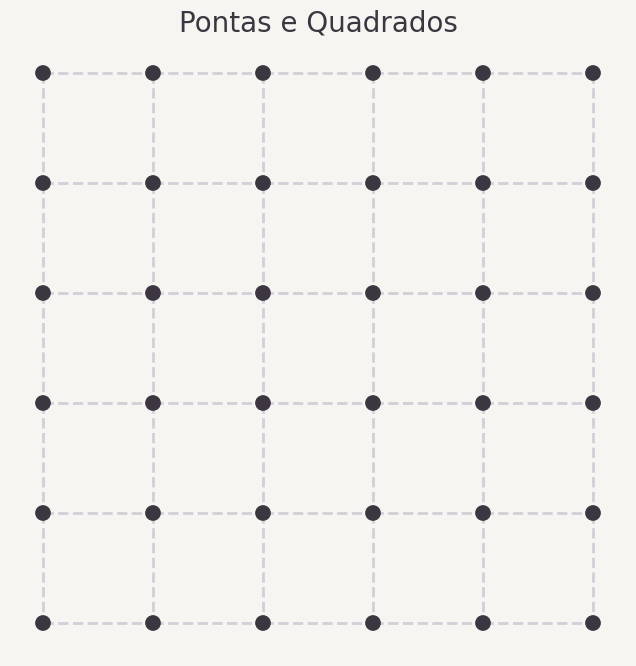

In [10]:
desenhar_tabuleiro(tabuleiro)